[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/09_pipeline-patterns.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 9 of 21*

# Pipeline Patterns

The heart of the job: idempotent loads, incremental processing, watermarks, merge and upsert, change data capture, backfills, late data, deduplication, dead-letter queues and designing for failure.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Assume every job will fail halfway and be run twice. Design so that neither matters.

**What interviewers really test here:** Idempotency, incremental loads, CDC, backfills and late data. This is the heart of data engineering interviews.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Idempotency: the most important word in pipelines *(Basics)*
- [ ] 2. Incremental loads: only what's new *(Core)*
- [ ] 3. Change data capture *(Core)*
- [ ] 4. Late data and backfills *(Core)*
- [ ] 5. Designing so that failure doesn't hurt users *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Loading patterns compared

| Pattern | Idempotent? | Handles deletes? | Use for |
| --- | --- | --- | --- |
| Full reload | yes | yes | small tables |
| Overwrite partition | yes | within the partition | immutable events by date |
| Append | no | no | only with a unique key to dedupe on |
| Upsert / MERGE | yes | if told | mutable records |
| CDC | if applied by key | yes | fresh copies of databases |

---
# Part 2: Lessons, step by step

## Lesson 1: Idempotency: the most important word in pipelines

*Level: Basics*

Pipelines fail and get rerun. Sometimes a scheduler even runs one twice. **Idempotent** means running it twice gives the same result as running it once.



Imagine a light switch labelled "turn on": pressing it again changes nothing. A switch labelled "toggle" isn't idempotent.



| Pattern | 3 rows, run twice | Idempotent? |
| --- | --- | --- |
| Plain append | **6 rows: every total doubled** | no |
| Overwrite the day's partition | 3 rows | yes |
| Upsert by key | 3 rows | yes |



This one idea prevents many of the data incidents you'll meet. If a teammate says "just rerun it", your first thought should be: is that safe?



**Overwrite a partition** is the simplest safe batch pattern. A job for 5 January deletes and rewrites only that day's data, and leaves others alone. Rerun it as many times as you like.



```python
INSERT OVERWRITE TABLE orders PARTITION (day = '2026-01-05')
SELECT ... WHERE day = '2026-01-05';
```



**Design rule:** make each run a pure function of its input and its date, and pass the date in as a parameter. Never use "today" in the logic, or reruns of old days will read the wrong data.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 2: Incremental loads: only what's new

*Level: Core*

Copying a 10 TB table every day is slow and expensive. If 1 TB changes, load just that.



| Approach | How | Trade-off |
| --- | --- | --- |
| Full load | replace everything | simple; catches deletes; gets expensive |
| Incremental | only new or changed rows | cheap; more logic; can miss things |
| CDC | read the database's log | complete and fresh; more infrastructure |



Don't optimise too early. A 3 GB table where incremental would still cost 3 GB should simply be fully reloaded.



**The high-watermark pattern:** remember the largest `updated_at` you've loaded, then ask for rows after it.



Rows at times 10, 20, 30, with watermark 15: load 20 and 30, and the new watermark is 30. If there are no new rows, keep the old one. Save it only **after** the load succeeds, or a crash would skip data.



**The trap: long transactions.** A row stamped time 95 might commit after you've already read up to 100, so a strict watermark misses it forever. So re-read with a **lookback window**: read from 90. You'll see some rows twice, which is fine, as long as you **apply with an idempotent upsert**.



**Upsert (MERGE)** updates existing keys and inserts new ones:



```python
MERGE INTO target t USING updates u ON t.id = u.id
WHEN MATCHED AND u.ts > t.ts THEN UPDATE SET ...
WHEN NOT MATCHED THEN INSERT ...;
```



The `u.ts > t.ts` condition matters. Updates can arrive out of order, and an old update mustn't overwrite a newer one.

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q9](#q9), [Q10](#q10), [Q7](#q7), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 3: Change data capture

*Level: Core*

Watermarks can't see **deleted** rows: a row that's gone doesn't show up in "changed since". And they miss intermediate changes.



**Change data capture (CDC)** reads the database's own log, which records every insert, update and delete, with little load on the source. Debezium is the best-known tool, usually writing to Kafka.



```text
App → Postgres → WAL → Debezium → Kafka → Consumer → Lake table
```



**Replaying events by hand,** starting from {1: a}:



| Event | State |
| --- | --- |
| create 2 = b | {1: a, 2: b} |
| update 1 = A | {1: A, 2: b} |
| delete 2 | {1: A} |
| create 3 = c | {1: A, 3: c} |



**Order matters per key,** so messages for one key must stay in order. In Kafka, you ensure this by using the primary key as the message key.



**Compaction before merging.** If a batch has several events per key, only the last matters: create then update becomes the update. A create then delete still needs the delete, in case that row existed before the batch.



**Soft deletes** mark a row as deleted rather than removing it, so downstream systems can see it went away. Hard deletes remain important for privacy laws, which you'll see later.



**No CDC available?** Compare snapshots by hashing rows, which is expensive but works: new ids, changed hashes, missing ids.

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q12](#q12), [Q3](#q3), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 4: Late data and backfills

*Level: Core*

**Late data is normal.** A phone offline for two days sends events from two days ago. If you've already closed that day, what do you do?



1. **Reprocess affected partitions:** find the event days among late rows, and rerun those days, which is easy if runs are idempotent.
2. **Set a limit:** after, say, 7 days, close the books. Older data goes to a separate table.
3. **Tell people:** numbers for recent days may still change.



**Backfills** reprocess history, because of a bug fix or a new column. Run them in pieces:



10 days in chunks of 4 gives [1–4], [5–8], [9–10].



- Small chunks mean failures lose little. Track what's finished, and **resume** where you stopped.
- Limit how many run at once, so you don't starve daily jobs or the source database.
- Write to a new location, compare with the old data, and then switch.



**Checkpoints.** With a batch of 3 and a crash after item 7, the last checkpoint is at 6, so only item 7 is redone: 11 processings for 10 items. Checkpoint more often and you redo less, but pay more overhead.



The chart shows the trade-off between how often you checkpoint and the work you'd lose.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

work lost per checkpoint size: {10: 7, 100: 17, 1000: 217, 10000: 3217, 50000: 23217}


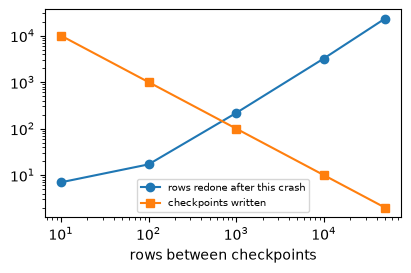

In [2]:
def checkpoint_tradeoff():
    n, crash = 100000, 73217
    sizes = np.array([10, 100, 1000, 10000, 50000])
    lost = crash % sizes
    overhead = n // sizes
    print("work lost per checkpoint size:", dict(zip(sizes.tolist(), lost.tolist())))
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.loglog(sizes, np.maximum(lost, 1), "o-", label="rows redone after this crash")
    ax.loglog(sizes, overhead, "s-", label="checkpoints written")
    ax.set_xlabel("rows between checkpoints")
    ax.legend(fontsize=7)


checkpoint_tradeoff()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q4](#q4), [Q17](#q17), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 5: Designing so that failure doesn't hurt users

*Level: Advanced*

**Dead-letter queues.** One corrupt message shouldn't stop a pipeline, so set it aside with its reason and carry on. But if a *large share* is bad, something's badly wrong, so halt. With a 50% limit, 1 bad in 3 continues, and 2 bad in 3 stops.



**Write-audit-publish (WAP).** Don't let users see data you haven't checked:



1. **Write** to a staging location.
2. **Audit:** run the quality checks.
3. **Publish** atomically, only if they pass.



If staged data contains a NULL id, users keep seeing yesterday's table, which is stale but correct. That's nearly always better than fresh but wrong.



**Atomic swap.** Readers must never see half a load. Build the new version off to the side, and then flip one pointer, such as a view or a table format's metadata. If the build fails, the pointer doesn't move.



**Dedupe in streams.** You can't remember every id forever, so keep ids for a time window (TTL). Event "a" at time 5 is a duplicate of time 1, with a 10-second TTL. At time 20 it's treated as new. Choose a TTL longer than the realistic delay of retries.



**Always reconcile** source and target per day. If source has d2 = 5 and target has d2 = 0, you've found the problem before your users do.



| Question for any pipeline | Good answer |
| --- | --- |
| Run it twice? | same result |
| Fails halfway? | rerun from the start or a checkpoint |
| Data arrives late? | affected days get reprocessed |
| Source sends garbage? | caught at the door, and doesn't reach users |
| How will I know? | alerts, not a user's email |

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q15](#q15), [Q20](#q20), [Q18](#q18), [Q5](#q5). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Naive Append Isn't Idempotent

🟢 Warm-up · *The classic bug*

Show the difference: running a load twice with append vs with overwrite-by-day. Return the row counts (append, overwrite). Rows are lists of ids.

**Examples**

- `rows = [1, 2, 3], runs = 2` → `(6, 3)`

In [ ]:
def append_vs_overwrite(rows, runs):
    """
    Show the difference: running a load twice with append vs with overwrite-by-
    day. Return the row counts (append, overwrite). Rows are lists of ids.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(append_vs_overwrite, [
    (([1, 2, 3], 2), (6, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate each with a list and a dictionary.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same simulation, compactly.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Simulate each with a list and a dictionary.

```python
def append_vs_overwrite(rows, runs):
    table = []
    for _ in range(runs):
        for r in rows:
            table.append(r)
    partition = {}
    for _ in range(runs):
        partition["day"] = list(rows)
    return (len(table), len(partition["day"]))
```

**Cost:** O(r·n) time, O(r·n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same simulation, compactly.

```python
def append_vs_overwrite(rows, runs):
    return (len(rows) * runs, len(rows))
```

**Cost:** O(r·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate each with a list and a dictionary. That costs O(r·n) time and O(r·n) space."

"I can do better: Same simulation, compactly. That's O(r·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/naive-append-isnt-idempotent)

<a id="q2"></a>
### Q2. Overwrite a Partition

🟢 Warm-up · *The simplest safe pattern*

table maps day to rows. Load new rows for a day, replacing any existing ones. Return the table with days sorted.

**Examples**

- `table = {'d1': [1], 'd2': [2, 3]}, day = 'd2', rows = [9]` → `{'d1': [1], 'd2': [9]}`
- `table = {'d1': [1]}, day = 'd3', rows = [7]` → `{'d1': [1], 'd3': [7]}`

In [ ]:
def overwrite_partition(table, day, rows):
    """
    table maps day to rows. Load new rows for a day, replacing any existing
    ones. Return the table with days sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(overwrite_partition, [
    (({'d1': [1], 'd2': [2, 3]}, 'd2', [9]), {'d1': [1], 'd2': [9]}),
    (({'d1': [1]}, 'd3', [7]), {'d1': [1], 'd3': [7]}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Rebuild the dictionary in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Merge with a dictionary union.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Rebuild the dictionary in a loop.

```python
def overwrite_partition(table, day, rows):
    out = {}
    for d in table:
        if d != day:
            out[d] = table[d]
    out[day] = rows
    return dict(sorted(out.items()))
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Merge with a dictionary union.

```python
def overwrite_partition(table, day, rows):
    return dict(sorted((table | {day: rows}).items()))
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Rebuild the dictionary in a loop. That costs O(d) time and O(d) space."

"I can do better: Merge with a dictionary union. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/overwrite-a-partition)

<a id="q3"></a>
### Q3. Soft Deletes

🟢 Warm-up · *Keep the history*

Mark rows deleted rather than removing them. Return (rows with deleted flags, ids of visible rows).

**Examples**

- `rows = [{'id': 1}, {'id': 2}], deleted = [2]` → `([{'id': 1, 'deleted': False}, {'id': 2, 'deleted': True}], [1])`

In [ ]:
def soft_delete(rows, deleted):
    """
    Mark rows deleted rather than removing them. Return (rows with deleted
    flags, ids of visible rows).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(soft_delete, [
    (([{'id': 1}, {'id': 2}], [2]), ([{'id': 1, 'deleted': False}, {'id': 2, 'deleted': True}], [1])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set for membership.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def soft_delete(rows, deleted):
    out = []
    for r in rows:
        out.append({**r, "deleted": r["id"] in deleted})
    return (out, [r["id"] for r in out if not r["deleted"]])
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A set for membership.

```python
def soft_delete(rows, deleted):
    gone = set(deleted)
    out = [{**r, "deleted": r["id"] in gone} for r in rows]
    return (out, [r["id"] for r in rows if r["id"] not in gone])
```

**Cost:** O(n + d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n·d) time and O(n) space."

"I can do better: A set for membership. That's O(n + d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/soft-deletes)

<a id="q4"></a>
### Q4. Find What's Left to Backfill

🟢 Warm-up · *Safe to resume*

Given days wanted and days done, return remaining days, sorted. A resumable job picks up here after a crash.

**Examples**

- `wanted = [1, 2, 3, 4], done = [2, 3]` → `[1, 4]`

In [ ]:
def remaining_days(wanted, done):
    """
    Given days wanted and days done, return remaining days, sorted. A resumable
    job picks up here after a crash.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(remaining_days, [
    (([1, 2, 3, 4], [2, 3]), [1, 4]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`not in` on a list.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set difference.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** `not in` on a list.

```python
def remaining_days(wanted, done):
    return sorted(d for d in wanted if d not in done)
```

**Cost:** O(n·m) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set difference.

```python
def remaining_days(wanted, done):
    return sorted(set(wanted) - set(done))
```

**Cost:** O(n + m) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `not in` on a list. That costs O(n·m) time and O(n) space."

"I can do better: Set difference. That's O(n + m) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/find-whats-left-to-backfill)

<a id="q5"></a>
### Q5. Reconcile Source and Target

🟢 Warm-up · *Did everything arrive?*

Compare per-day counts. Return days where they differ, as [day, source, target], sorted. Missing days count as 0.

**Examples**

- `source = {'d1': 10, 'd2': 5}, target = {'d1': 10, 'd3': 2}` → `[['d2', 5, 0], ['d3', 0, 2]]`

In [ ]:
def reconcile(source, target):
    """
    Compare per-day counts. Return days where they differ, as [day, source,
    target], sorted. Missing days count as 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(reconcile, [
    (({'d1': 10, 'd2': 5}, {'d1': 10, 'd3': 2}), [['d2', 5, 0], ['d3', 0, 2]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Union of keys in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension over the union.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Union of keys in a loop.

```python
def reconcile(source, target):
    out = []
    for d in sorted(set(source) | set(target)):
        a, b = source.get(d, 0), target.get(d, 0)
        if a != b:
            out.append([d, a, b])
    return out
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension over the union.

```python
def reconcile(source, target):
    return [[d, source.get(d, 0), target.get(d, 0)] for d in sorted(source.keys() | target.keys()) if source.get(d, 0) != target.get(d, 0)]
```

**Cost:** O(d log d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Union of keys in a loop. That costs O(d) time and O(d) space."

"I can do better: A comprehension over the union. That's O(d log d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/reconcile-source-and-target)

<a id="q6"></a>
### Q6. Choose Full or Incremental

🟢 Warm-up · *Simple until it isn't*

Compare daily costs: a full load reads total\_gb; an incremental load reads changed\_gb plus overhead\_gb. Return the cheaper option and its GB; on a tie, prefer 'full' for simplicity.

**Examples**

- `total_gb = 10, changed_gb = 1, overhead_gb = 2` → `['incremental', 3]`
- `total_gb = 3, changed_gb = 1, overhead_gb = 2` → `['full', 3]`

In [ ]:
def full_or_incremental(total_gb, changed_gb, overhead_gb):
    """
    Compare daily costs: a full load reads total_gb; an incremental load reads
    changed_gb plus overhead_gb. Return the cheaper option and its GB; on a tie,
    prefer 'full' for simplicity.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(full_or_incremental, [((10, 1, 2), ['incremental', 3]), ((3, 1, 2), ['full', 3])], post=list)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A conditional expression.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def full_or_incremental(total_gb, changed_gb, overhead_gb):
    inc = changed_gb + overhead_gb
    if inc < total_gb:
        return ("incremental", inc)
    return ("full", total_gb)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A conditional expression.

```python
def full_or_incremental(total_gb, changed_gb, overhead_gb):
    inc = changed_gb + overhead_gb
    return ("incremental", inc) if inc < total_gb else ("full", total_gb)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(1) time and O(1) space."

"I can do better: A conditional expression. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/choose-full-or-incremental)

<a id="q7"></a>
### Q7. Upsert (MERGE)

🟡 Interview standard · *Insert or update by key*

Merge incoming rows into target by id: update existing, insert new. Return (rows sorted by id, inserted count, updated count).

**Examples**

- `target = [{'id': 1, 'v': 'a'}, {'id': 2, 'v': 'b'}], incoming = [{'id': 2, 'v': 'B'}, {'id': 3, 'v': 'c'}]` → `([{'id': 1, 'v': 'a'}, {'id': 2, 'v': 'B'}, {'id': 3, 'v': 'c'}], 1, 1)`

In [ ]:
def upsert(target, incoming):
    """
    Merge incoming rows into target by id: update existing, insert new. Return
    (rows sorted by id, inserted count, updated count).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(upsert, [
    (([{'id': 1, 'v': 'a'}, {'id': 2, 'v': 'b'}], [{'id': 2, 'v': 'B'}, {'id': 3, 'v': 'c'}]), ([{'id': 1, 'v': 'a'}, {'id': 2, 'v': 'B'}, {'id': 3, 'v': 'c'}], 1, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Search the target for each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary keyed by id.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Search the target for each row.

```python
def upsert(target, incoming):
    out = [dict(r) for r in target]
    inserted = updated = 0
    for row in incoming:
        for existing in out:
            if existing["id"] == row["id"]:
                existing.update(row)
                updated += 1
                break
        else:
            out.append(dict(row))
            inserted += 1
    return (sorted(out, key=lambda r: r["id"]), inserted, updated)
```

**Cost:** O(n·m) time, O(n + m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary keyed by id.

```python
def upsert(target, incoming):
    table = {r["id"]: r for r in target}
    updated = sum(r["id"] in table for r in incoming)
    table.update({r["id"]: r for r in incoming})
    return ([table[k] for k in sorted(table)], len(incoming) - updated, updated)
```

**Cost:** O(n + m) time, O(n + m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Search the target for each row. That costs O(n·m) time and O(n + m) space."

"I can do better: A dictionary keyed by id. That's O(n + m) time and O(n + m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/upsert-merge)

<a id="q8"></a>
### Q8. Upsert Keeps Only Newer

🟡 Interview standard · *Out-of-order updates*

Rows have id, v and ts. Apply incoming only if its ts is newer than what's stored. Return rows by id.

**Examples**

- `target = [{'id': 1, 'v': 'new', 'ts': 20}], incoming = [{'id': 1, 'v': 'old', 'ts': 10}, {'id': 2, 'v': 'x', 'ts': 5}]` → `[{'id': 1, 'v': 'new', 'ts': 20}, {'id': 2, 'v': 'x', 'ts': 5}]`

In [ ]:
def upsert_newer(target, incoming):
    """
    Rows have id, v and ts. Apply incoming only if its ts is newer than what's
    stored. Return rows by id.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(upsert_newer, [
    (([{'id': 1, 'v': 'new', 'ts': 20}], [{'id': 1, 'v': 'old', 'ts': 10}, {'id': 2, 'v': 'x', 'ts': 5}]), [{'id': 1, 'v': 'new', 'ts': 20}, {'id': 2, 'v': 'x', 'ts': 5}]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Search for each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary with a comparison.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Search for each row.

```python
def upsert_newer(target, incoming):
    out = [dict(r) for r in target]
    for row in incoming:
        for existing in out:
            if existing["id"] == row["id"]:
                if row["ts"] > existing["ts"]:
                    existing.update(row)
                break
        else:
            out.append(dict(row))
    return sorted(out, key=lambda r: r["id"])
```

**Cost:** O(n·m) time, O(n + m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary with a comparison.

```python
def upsert_newer(target, incoming):
    table = {r["id"]: r for r in target}
    for r in incoming:
        if r["id"] not in table or r["ts"] > table[r["id"]]["ts"]:
            table[r["id"]] = r
    return [table[k] for k in sorted(table)]
```

**Cost:** O(n + m) time, O(n + m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Search for each row. That costs O(n·m) time and O(n + m) space."

"I can do better: A dictionary with a comparison. That's O(n + m) time and O(n + m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/upsert-keeps-only-newer)

<a id="q9"></a>
### Q9. High-Watermark Incremental Load

🟡 Interview standard · *Only what's new*

Rows have (id, updated). Given the last watermark, return (rows to load, new watermark). Rows with updated &gt; watermark are new. If there are none, the watermark stays.

**Examples**

- `rows = [(1, 10), (2, 20), (3, 30)], watermark = 15` → `([(2, 20), (3, 30)], 30)`
- `rows = [(1, 10)], watermark = 15` → `([], 15)`

In [ ]:
def incremental(rows, watermark):
    """
    Rows have (id, updated). Given the last watermark, return (rows to load, new
    watermark). Rows with updated > watermark are new. If there are none, the
    watermark stays.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(incremental, [
    (([(1, 10), (2, 20), (3, 30)], 15), ([(2, 20), (3, 30)], 30)),
    (([(1, 10)], 15), ([], 15)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop tracking the maximum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension, then `max` with a default.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop tracking the maximum.

```python
def incremental(rows, watermark):
    new, high = [], watermark
    for r in rows:
        if r[1] > watermark:
            new.append(r)
            if r[1] > high:
                high = r[1]
    return (new, high)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension, then `max` with a default.

```python
def incremental(rows, watermark):
    new = [r for r in rows if r[1] > watermark]
    return (new, max((r[1] for r in new), default=watermark))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop tracking the maximum. That costs O(n) time and O(k) space."

"I can do better: A comprehension, then `max` with a default. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/high-watermark-incremental-load)

<a id="q10"></a>
### Q10. Watermark With a Lookback

🟡 Interview standard · *Don't miss late rows*

A strict watermark misses rows committed late with an older timestamp. Re-read with a lookback: rows with updated &gt; watermark − lookback. Then dedupe by id, keeping the latest. Return ids to apply, sorted.

**Examples**

- `rows = [(1, 100), (2, 95), (3, 120)], watermark = 100, lookback = 10, applied = {1: 100}` → `[2, 3]`

In [ ]:
def lookback_ids(rows, watermark, lookback, applied):
    """
    A strict watermark misses rows committed late with an older timestamp. Re-
    read with a lookback: rows with updated > watermark − lookback. Then dedupe
    by id, keeping the latest. Return ids to apply, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lookback_ids, [
    (([(1, 100), (2, 95), (3, 120)], 100, 10, {1: 100}), [2, 3]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Filter and compare in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension, skipping rows already applied at that version.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Filter and compare in loops.

```python
def lookback_ids(rows, watermark, lookback, applied):
    out = []
    for i, ts in rows:
        if ts > watermark - lookback and applied.get(i) != ts:
            out.append(i)
    return sorted(out)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension, skipping rows already applied at that version.

```python
def lookback_ids(rows, watermark, lookback, applied):
    return sorted(i for i, ts in rows if ts > watermark - lookback and applied.get(i) != ts)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Filter and compare in loops. That costs O(n) time and O(n) space."

"I can do better: A comprehension, skipping rows already applied at that version. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/watermark-with-a-lookback)

<a id="q11"></a>
### Q11. Apply Change Data Capture

🟡 Interview standard · *Replay inserts, updates and deletes*

Events are (op, id, value), with op in 'c' create, 'u' update, 'd' delete, in log order. Apply them to a state dictionary. Return it sorted.

**Examples**

- `state = {1: 'a'}, events = [('c', 2, 'b'), ('u', 1, 'A'), ('d', 2, None), ('c', 3, 'c')]` → `{1: 'A', 3: 'c'}`

In [ ]:
def apply_cdc(state, events):
    """
    Events are (op, id, value), with op in 'c' create, 'u' update, 'd' delete,
    in log order. Apply them to a state dictionary. Return it sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(apply_cdc, [
    (({1: 'a'}, [('c', 2, 'b'), ('u', 1, 'A'), ('d', 2, None), ('c', 3, 'c')]), {1: 'A', 3: 'c'}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs for each operation.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same logic, with a compact conditional.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs for each operation.

```python
def apply_cdc(state, events):
    out = dict(state)
    for op, key, value in events:
        if op == "c" or op == "u":
            out[key] = value
        elif op == "d":
            if key in out:
                del out[key]
    return dict(sorted(out.items()))
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same logic, with a compact conditional.

```python
def apply_cdc(state, events):
    out = dict(state)
    for op, key, value in events:
        out.pop(key, None) if op == "d" else out.__setitem__(key, value)
    return dict(sorted(out.items()))
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs for each operation. That costs O(n) time and O(s) space."

"I can do better: Same logic, with a compact conditional. That's O(n) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/apply-change-data-capture)

<a id="q12"></a>
### Q12. Compact a CDC Batch

🟡 Interview standard · *Last event per key wins*

Reduce events to the final operation per id, in id order. A key created then deleted in the same batch still needs a delete in case it existed before.

**Examples**

- `events = [('c', 1, 'a'), ('u', 1, 'b'), ('c', 2, 'x'), ('d', 2, None)]` → `[['u', 1, 'b'], ['d', 2, None]]`

In [ ]:
def compact_cdc(events):
    """
    Reduce events to the final operation per id, in id order. A key created then
    deleted in the same batch still needs a delete in case it existed before.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(compact_cdc, [
    (([('c', 1, 'a'), ('u', 1, 'b'), ('c', 2, 'x'), ('d', 2, None)],), [['u', 1, 'b'], ['d', 2, None]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each id, scan for its last event.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary overwrites as it goes.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** For each id, scan for its last event.

```python
def compact_cdc(events):
    ids = sorted({e[1] for e in events})
    out = []
    for i in ids:
        last = None
        for e in events:
            if e[1] == i:
                last = e
        out.append(list(last))
    return out
```

**Cost:** O(n²) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary overwrites as it goes.

```python
def compact_cdc(events):
    last = {e[1]: e for e in events}
    return [list(last[k]) for k in sorted(last)]
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each id, scan for its last event. That costs O(n²) time and O(k) space."

"I can do better: A dictionary overwrites as it goes. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/compact-a-cdc-batch)

<a id="q13"></a>
### Q13. Plan a Backfill

🟡 Interview standard · *Reprocess history in pieces*

Split days from start to end (integers, inclusive) into batches of size at most chunk, as [first, last] pairs.

**Examples**

- `start = 1, end = 10, chunk = 4` → `[[1, 4], [5, 8], [9, 10]]`
- `start = 5, end = 5, chunk = 3` → `[[5, 5]]`

In [ ]:
def backfill_plan(start, end, chunk):
    """
    Split days from start to end (integers, inclusive) into batches of size at
    most chunk, as [first, last] pairs.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(backfill_plan, [
    ((1, 10, 4), [[1, 4], [5, 8], [9, 10]]),
    ((5, 5, 3), [[5, 5]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A while loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`range` with a step.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A while loop.

```python
def backfill_plan(start, end, chunk):
    out = []
    a = start
    while a <= end:
        b = a + chunk - 1
        if b > end:
            b = end
        out.append([a, b])
        a = b + 1
    return out
```

**Cost:** O(d/c) time, O(d/c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `range` with a step.

```python
def backfill_plan(start, end, chunk):
    return [[a, min(a + chunk - 1, end)] for a in range(start, end + 1, chunk)]
```

**Cost:** O(d/c) time, O(d/c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A while loop. That costs O(d/c) time and O(d/c) space."

"I can do better: `range` with a step. That's O(d/c) time and O(d/c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/plan-a-backfill)

<a id="q14"></a>
### Q14. Write-Audit-Publish

🟡 Interview standard · *Never show bad data*

Write to a staging list, audit with checks, and only publish if all pass. Return (published table, failed checks). Checks here: no null ids, and row count ≥ min\_rows.

**Examples**

- `current = [1, 2], staged = [3, 4], min_rows = 1` → `([3, 4], [])`
- `current = [1, 2], staged = [3, None], min_rows = 1` → `([1, 2], ['null_id'])`
- `current = [1, 2], staged = [], min_rows = 1` → `([1, 2], ['too_few_rows'])`

In [ ]:
def write_audit_publish(current, staged, min_rows):
    """
    Write to a staging list, audit with checks, and only publish if all pass.
    Return (published table, failed checks). Checks here: no null ids, and row
    count ≥ min_rows.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(write_audit_publish, [
    (([1, 2], [3, 4], 1), ([3, 4], [])),
    (([1, 2], [3, None], 1), ([1, 2], ['null_id'])),
    (([1, 2], [], 1), ([1, 2], ['too_few_rows'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A sequence of ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary of checks.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A sequence of ifs.

```python
def write_audit_publish(current, staged, min_rows):
    failed = []
    if None in staged:
        failed.append("null_id")
    if len(staged) < min_rows:
        failed.append("too_few_rows")
    if failed:
        return (current, failed)
    return (staged, failed)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary of checks.

```python
def write_audit_publish(current, staged, min_rows):
    checks = {"null_id": None not in staged, "too_few_rows": len(staged) >= min_rows}
    failed = [n for n, ok in checks.items() if not ok]
    return (current if failed else staged, failed)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A sequence of ifs. That costs O(n) time and O(n) space."

"I can do better: A dictionary of checks. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/write-audit-publish)

<a id="q15"></a>
### Q15. Dead-Letter Queue

🟡 Interview standard · *One bad row shouldn't stop the pipeline*

Process messages, sending failures to a dead-letter list with the reason. Stop if the bad share exceeds max\_bad. Return (good, dead-letter, status 'ok' or 'halted').

**Examples**

- `messages = ['1', 'x', '3'], max_bad = 0.5` → `([1, 3], [['x', 'not a number']], 'ok')`
- `messages = ['x', 'y', '3'], max_bad = 0.5` → `([3], [['x', 'not a number'], ['y', 'not a number']], 'halted')`

In [ ]:
def dlq(messages, max_bad):
    """
    Process messages, sending failures to a dead-letter list with the reason.
    Stop if the bad share exceeds max_bad. Return (good, dead-letter, status
    'ok' or 'halted').
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dlq, [
    ((['1', 'x', '3'], 0.5), ([1, 3], [['x', 'not a number']], 'ok')),
    ((['x', 'y', '3'], 0.5), ([3], [['x', 'not a number'], ['y', 'not a number']], 'halted')),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop, then a check.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The same, with a small parse helper.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop, then a check.

```python
def dlq(messages, max_bad):
    good, dead = [], []
    for m in messages:
        try:
            good.append(int(m))
        except ValueError:
            dead.append([m, "not a number"])
    status = "halted" if len(dead) / len(messages) > max_bad else "ok"
    return (good, dead, status)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** The same, with a small parse helper.

```python
def dlq(messages, max_bad):
    good = [int(m) for m in messages if m.lstrip("-").isdigit()]
    dead = [[m, "not a number"] for m in messages if not m.lstrip("-").isdigit()]
    return (good, dead, "halted" if len(dead) > max_bad * len(messages) else "ok")
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop, then a check. That costs O(n) time and O(n) space."

"I can do better: The same, with a small parse helper. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/dead-letter-queue)

<a id="q16"></a>
### Q16. Row Hash for Change Detection

🟡 Interview standard · *What actually changed?*

Compare snapshots keyed by id: hash each row's values with md5 of 'a|b' style. Return (new ids, changed ids, removed ids), sorted.

**Examples**

- `old = {1: ['a', 'b'], 2: ['c', 'd']}, new = {1: ['a', 'B'], 3: ['e', 'f'], 2: ['c', 'd']}` → `([3], [1], [])`

In [ ]:
import hashlib

def diff_snapshots(old, new):
    """
    Compare snapshots keyed by id: hash each row's values with md5 of 'a|b'
    style. Return (new ids, changed ids, removed ids), sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(diff_snapshots, [
    (({1: ['a', 'b'], 2: ['c', 'd']}, {1: ['a', 'B'], 3: ['e', 'f'], 2: ['c', 'd']}), ([3], [1], [])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare values directly in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Hash once, then set operations.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compare values directly in loops.

```python
def diff_snapshots(old, new):
    def h(values):
        return hashlib.md5("|".join(values).encode()).hexdigest()
    added, changed, removed = [], [], []
    for k in new:
        if k not in old:
            added.append(k)
        elif h(new[k]) != h(old[k]):
            changed.append(k)
    for k in old:
        if k not in new:
            removed.append(k)
    return (sorted(added), sorted(changed), sorted(removed))
```

**Cost:** O(n·c) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Hash once, then set operations.

```python
def diff_snapshots(old, new):
    h = lambda v: hashlib.md5("|".join(v).encode()).hexdigest()
    a, b = {k: h(v) for k, v in old.items()}, {k: h(v) for k, v in new.items()}
    return (sorted(b.keys() - a.keys()), sorted(k for k in a.keys() & b.keys() if a[k] != b[k]), sorted(a.keys() - b.keys()))
```

**Cost:** O(n·c) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare values directly in loops. That costs O(n·c) time and O(n) space."

"I can do better: Hash once, then set operations. That's O(n·c) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/row-hash-for-change-detection)

<a id="q17"></a>
### Q17. Which Partitions to Rerun?

🟡 Interview standard · *Late data*

Given late rows with event days, and a table of already-loaded days, return the days to reprocess, sorted, ignoring those older than the retention limit.

**Examples**

- `late_days = [5, 3, 3, 1], loaded = [1, 2, 3, 4, 5], oldest = 2` → `[3, 5]`

In [ ]:
def rerun_days(late_days, loaded, oldest):
    """
    Given late rows with event days, and a table of already-loaded days, return
    the days to reprocess, sorted, ignoring those older than the retention
    limit.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rerun_days, [
    (([5, 3, 3, 1], [1, 2, 3, 4, 5], 2), [3, 5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Filter in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set operations.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Filter in a loop.

```python
def rerun_days(late_days, loaded, oldest):
    out = []
    for d in late_days:
        if d in loaded and d >= oldest and d not in out:
            out.append(d)
    return sorted(out)
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set operations.

```python
def rerun_days(late_days, loaded, oldest):
    return sorted(d for d in set(late_days) & set(loaded) if d >= oldest)
```

**Cost:** O(n + d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Filter in a loop. That costs O(n·d) time and O(n) space."

"I can do better: Set operations. That's O(n + d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/which-partitions-to-rerun)

<a id="q18"></a>
### Q18. Atomic Swap

🟡 Interview standard · *Readers never see half a load*

Simulate: build a new table version, then flip a pointer. If the build fails midway, the pointer doesn't move. Return (current version's data, pointer).

**Examples**

- `versions = {'v1': [1, 2]}, pointer = 'v1', new_rows = [3, 4], build_ok = True` → `([3, 4], 'v2')`
- `versions = {'v1': [1, 2]}, pointer = 'v1', new_rows = [3, 4], build_ok = False` → `([1, 2], 'v1')`

In [ ]:
def atomic_swap(versions, pointer, new_rows, build_ok):
    """
    Simulate: build a new table version, then flip a pointer. If the build fails
    midway, the pointer doesn't move. Return (current version's data, pointer).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(atomic_swap, [
    (({'v1': [1, 2]}, 'v1', [3, 4], True), ([3, 4], 'v2')),
    (({'v1': [1, 2]}, 'v1', [3, 4], False), ([1, 2], 'v1')),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def atomic_swap(versions, pointer, new_rows, build_ok):
    store = dict(versions)
    if build_ok:
        name = "v" + str(len(store) + 1)
        store[name] = new_rows
        pointer = name
    return (store[pointer], pointer)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact.

```python
def atomic_swap(versions, pointer, new_rows, build_ok):
    return (new_rows, f"v{len(versions) + 1}") if build_ok else (versions[pointer], pointer)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(n) time and O(n) space."

"I can do better: Compact. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/atomic-swap)

<a id="q19"></a>
### Q19. Checkpoint and Resume

🟡 Interview standard · *Don't start from zero*

Process items, saving a checkpoint after each batch. Simulate a crash at crash\_at items processed, then resume from the last checkpoint. Return (total item-processings, items reprocessed).

**Examples**

- `n = 10, batch = 3, crash_at = 7` → `(11, 1)`
- `n = 10, batch = 5, crash_at = 5` → `(10, 0)`

In [ ]:
def checkpoint_cost(n, batch, crash_at):
    """
    Process items, saving a checkpoint after each batch. Simulate a crash at
    crash_at items processed, then resume from the last checkpoint. Return
    (total item-processings, items reprocessed).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(checkpoint_cost, [
    ((10, 3, 7), (11, 1)),
    ((10, 5, 5), (10, 0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Reprocessed = crash\_at mod batch.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Simulate in a loop.

```python
def checkpoint_cost(n, batch, crash_at):
    done = checkpoint = 0
    while done < crash_at:
        done += 1
        if done % batch == 0:
            checkpoint = done
    redo = done - checkpoint
    return (done + (n - checkpoint), redo)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Reprocessed = crash\_at mod batch.

```python
def checkpoint_cost(n, batch, crash_at):
    redo = crash_at % batch
    return (n + redo, redo)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate in a loop. That costs O(n) time and O(1) space."

"I can do better: Reprocessed = crash\_at mod batch. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/checkpoint-and-resume)

<a id="q20"></a>
### Q20. Dedupe a Stream With a TTL

🔴 Stretch · *Don't remember forever*

Events are (id, time). Drop an event if the same id was seen within ttl seconds. Return kept events. Memory must stay bounded in a real system, by evicting expired ids.

**Examples**

- `events = [('a', 1), ('b', 2), ('a', 5), ('a', 20)], ttl = 10` → `[['a', 1], ['b', 2], ['a', 20]]`

In [ ]:
def ttl_dedupe(events, ttl):
    """
    Events are (id, time). Drop an event if the same id was seen within ttl
    seconds. Return kept events. Memory must stay bounded in a real system, by
    evicting expired ids.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ttl_dedupe, [
    (([('a', 1), ('b', 2), ('a', 5), ('a', 20)], 10), [['a', 1], ['b', 2], ['a', 20]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan earlier kept events each time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary of last-kept time per id.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan earlier kept events each time.

```python
def ttl_dedupe(events, ttl):
    kept = []
    for i, t in events:
        recent = [k for k in kept if k[0] == i and t - k[1] <= ttl]
        if not recent:
            kept.append([i, t])
    return kept
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary of last-kept time per id.

```python
def ttl_dedupe(events, ttl):
    last, kept = {}, []
    for i, t in events:
        if i not in last or t - last[i] > ttl:
            kept.append([i, t])
            last[i] = t
    return kept
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan earlier kept events each time. That costs O(n²) time and O(n) space."

"I can do better: A dictionary of last-kept time per id. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/pipeline-patterns/dedupe-a-stream-with-a-ttl)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What does idempotent mean, and why does it matter?</b></summary>

Running a job repeatedly gives the same result as running it once. Pipelines fail and get retried, so this makes recovery safe.

</details>

<details>
<summary><b>2. How do you make a pipeline idempotent?</b></summary>

Overwrite a partition, or upsert on a unique key. Parameterise by date rather than using the current time, and avoid side effects such as blind appends.

</details>

<details>
<summary><b>3. Full vs incremental load?</b></summary>

Full is simple and catches deletes, but costs grow with table size. Incremental is efficient, but more complex, and it can miss deletes and late rows.

</details>

<details>
<summary><b>4. What is CDC, and why use it?</b></summary>

Reading a database's transaction log to capture every change. It sees deletes and intermediate states, with low load on the source, and it enables near real-time copies.

</details>

<details>
<summary><b>5. How do you handle late-arriving data?</b></summary>

Use event time, reprocess affected partitions, set a cut-off, and make runs idempotent. In streaming, use watermarks.

</details>

<details>
<summary><b>6. What is write-audit-publish?</b></summary>

Write to staging, run quality checks, then publish atomically only on success, so users never see unverified data.

</details>

<details>
<summary><b>7. Scenario: a job failed halfway and left partial data. How do you recover?</b></summary>

If it's idempotent, simply rerun it. If it isn't, find what was written, delete it, fix the job so that it's idempotent, and add atomic publishing.

</details>

<details>
<summary><b>8. Scenario: revenue doubled for one day. What's your first guess?</b></summary>

A rerun with append, or a duplicated source file. Check duplicates on the unique key and the load history, then replace that partition and fix the pattern.

</details>

<details>
<summary><b>9. Scenario: you need to backfill 2 years without affecting production. How?</b></summary>

Split it into chunks, limit concurrency, schedule off-peak, write to a separate table, compare with existing data, then swap atomically. Make it resumable.

</details>

<details>
<summary><b>10. Scenario: your incremental load keeps missing a few rows each day. Why?</b></summary>

Likely long transactions committing with older timestamps, or clock differences. Add a lookback window with an idempotent merge, or move to CDC.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Idempotency: the most important word in pipelines
- [ ] I can explain: Incremental loads: only what's new
- [ ] I can explain: Change data capture
- [ ] I can explain: Late data and backfills
- [ ] I can explain: Designing so that failure doesn't hurt users

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Row Hash for Change Detection
- [ ] [Q17](#q17) Which Partitions to Rerun?
- [ ] [Q18](#q18) Atomic Swap
- [ ] [Q19](#q19) Checkpoint and Resume
- [ ] [Q20](#q20) Dedupe a Stream With a TTL

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.